# B13 – Phát Hiện Tấn Công Mạng Bằng K-Nearest Neighbors (KNN)
## Phân Loại Nhị Phân – Dataset CICMAL2017

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════

# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
ROOT_DIR = Path.cwd()
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "category_CICMAL2017_dataset.csv",
    ROOT_DIR / "Dataset" / "category_CICMAL2017_dataset.csv",
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

# ==========================
# NHÃN (LABELS)
# ==========================
# Binary Label: 0 = Benign (bình thường), 1 = Malware (mã độc)
LABEL_COL = "Binary Label"
TARGET_NAMES = ["Benign", "Malware"]

# ==========================
# CÁC CỘT KHÔNG DÙNG LÀM FEATURE
# ==========================
# Cột định danh và nhãn đa lớp — đưa vào mô hình sẽ gây rò rỉ nhãn
META_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp", "Cat_Label"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 70% train / 30% test
CV_FOLDS = 5       # số fold của cross-validation

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ KNN
# ==========================
K_GRID = [1, 3, 5, 7, 9, 11, 15, 21, 31]            # số láng giềng cần quét
METRICS = ["euclidean", "manhattan", "chebyshev"]    # metric khoảng cách
WEIGHTS = ["uniform", "distance"]                    # trọng số phiếu bầu
PCA_GRID = [2, 5, 10, 20]                            # số chiều PCA cần thử

# ==========================
# GIỚI HẠN TRỤC BIỂU ĐỒ
# ==========================
SCALE_YLIM = (0.95, 1.0)
COMBO_XLIM = (0.98, 1.0)

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
SCALE_COMMENT = (
    "\nNhận xét: hai giá trị gần như trùng nhau. Quy tắc \"KNN luôn phải chuẩn\n"
    "hóa\" KHÔNG đúng với bộ dữ liệu này. Lý do: những đặc trưng có biên độ lớn\n"
    "nhất ở đây (Flow Duration, Total Length of Fwd Packets...) đồng thời cũng là\n"
    "những đặc trưng phân biệt tốt nhất, nên việc chúng áp đảo khoảng cách lại\n"
    "vô tình có lợi. Vẫn nên chuẩn hóa vì ta không biết trước điều đó.")
KSWEEP_COMMENT = (
    "\nNhận xét: k nhỏ thắng, nhưng chênh lệch giữa k tốt nhất và k = 31 chỉ\n"
    "khoảng 0,003 → mô hình không quá nhạy với k trên bộ dữ liệu này. Đường cong\n"
    "có đỉnh rồi đi xuống nhẹ là dạng bình thường, lành mạnh.")
COMBO_COMMENT = (
    "\nNhận xét: Manhattan (L1) vượt Euclidean (L2). Khi số chiều lớn, L2 cộng\n"
    "dồn bình phương nên một chiều nhiễu mạnh có thể chi phối toàn bộ khoảng\n"
    "cách; L1 phân bổ đều hơn giữa các chiều. Chebyshev kém nhất vì chỉ nghe\n"
    "theo đúng một chiều.")
PCA_COMMENT = (
    "\nNhận xét: giảm xuống 10 chiều cho F1 CAO HƠN dùng toàn bộ đặc trưng, dù\n"
    "chỉ giữ khoảng 75% phương sai. Đây chính là lời nguyền số chiều: các chiều\n"
    "bị loại chủ yếu mang nhiễu, và loại chúng làm khoảng cách sạch hơn.")
LATENCY_COMMENT = (
    "\nNhận xét: với khoảng 15.000 mẫu train, mỗi dự đoán mất chừng 0,1 ms trên\n"
    "một luồng xử lý — tương đương khoảng 10.000 luồng/giây. Một IDS đường trục\n"
    "cần xử lý hàng trăm nghìn luồng/giây và sẽ tích lũy hàng triệu mẫu lịch sử,\n"
    "lúc đó KNN không còn khả thi. Cây quyết định hay hồi quy logistic có chi phí\n"
    "dự đoán hằng số nên phù hợp hơn cho triển khai trực tuyến.")
FINAL_COMMENT = (
    "\nNhận xét: KNN gần như bằng Random Forest về F1, nhưng AUC thấp hơn rõ.\n"
    "Nguyên nhân: predict_proba của KNN với k nhỏ chỉ nhận được vài giá trị rời\n"
    "rạc (k = 3 → chỉ 0, 1/3, 2/3, 1), nên mô hình gần như không xếp hạng được\n"
    "mức độ nghi ngờ giữa các mẫu. Với SOC cần sắp thứ tự ưu tiên cảnh báo, đó\n"
    "là một hạn chế đáng kể.")
KFOLD_COMMENT = (
    "\nNhận xét: độ lệch chuẩn rất nhỏ → kết quả ổn định qua các lần chia khác\n"
    "nhau, không phải do may mắn của một lần chia duy nhất.")

print("✅ Cấu hình xong!")
print(f"   Dataset    → {CSV_PATH}")
print(f"   Nhãn       → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size  → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   K_GRID     → {K_GRID}")


✅ Cấu hình xong!
   Dataset    → c:\Desktop\VANN\BÀI THỰC HÀNH C07\CV4.1\CV4.1\Dataset\category_CICMAL2017_dataset.csv
   Nhãn       → Binary Label (0 = Benign, 1 = Malware)
   Test size  → 30%  |  SEED = 42  |  CV folds = 5
   K_GRID     → [1, 3, 5, 7, 9, 11, 15, 21, 31]


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Làm sạch DataFrame và trả về ma trận đặc trưng CHƯA chuẩn hóa:
      1. Chỉ giữ cột số, loại cột meta và cột nhãn
      2. Thay Inf / -Inf → NaN
      3. Điền giá trị thiếu bằng median
      4. Loại cột phương sai = 0 (hằng số → không đóng góp vào khoảng cách)

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó thay vì tự chọn.
    Dùng cho tập held-out — tập này buộc phải có đúng bộ đặc trưng của tập
    train, nếu không scaler và mô hình sẽ lệch chiều.

    Trả về: (X_raw, danh sách cột bị loại vì phương sai = 0)
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
def evaluate(y_true, y_pred, y_score, name=""):
    """Tính Accuracy / Precision / Recall / F1 / F1-macro / AUC-ROC."""
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


# ════════════════════════════════════════════════════════════════════════════
# HÀM HUẤN LUYỆN KNN
# ════════════════════════════════════════════════════════════════════════════
def fit_knn(X_train, y_train, X_eval, n_neighbors=5, metric="euclidean",
            weights="uniform"):
    """Huấn luyện KNN rồi trả về (nhãn dự đoán, xác suất lớp 1, model).

    Lưu ý: fit() của KNN gần như tức thì vì nó chỉ dựng cấu trúc tìm kiếm
    trên tập train, không tối ưu tham số nào. Chi phí thật nằm ở predict().
    """
    kn = KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric,
                              weights=weights)
    kn.fit(X_train, y_train)
    y_pred = kn.predict(X_eval)
    y_score = kn.predict_proba(X_eval)[:, 1]
    return y_pred, y_score, kn


print("✅ Đã định nghĩa clean_numeric(), evaluate(), fit_knn()")


✅ Đã định nghĩa clean_numeric(), evaluate(), fit_knn()


---
# Xây Dựng Mô Hình KNN

> **Bài toán:** Dự đoán một luồng mạng là **Benign (0)** hay **Malware (1)**
>
> **Ý tưởng của KNN:** một luồng mạng bị coi là mã độc nếu phần lớn trong `k` luồng *giống nó nhất* đã từng quan sát là mã độc. Mô hình không học quy luật nào — nó chỉ ghi nhớ và so sánh.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CICMAL2017")
print("═" * 70)

df = pd.read_csv(CSV_PATH, low_memory=False)
y = df[LABEL_COL].astype(int).values

print(f"Shape gốc : {df.shape}")
print(f"\nPhân phối nhãn gốc:")
print(f"   {TARGET_NAMES[0]}(0) : {int((y == 0).sum()):,}")
print(f"   {TARGET_NAMES[1]}(1) : {int((y == 1).sum()):,}")
print(f"   Tỷ lệ mã độc  : {(y == 1).mean()*100:.2f}%")
print("\n5 họ mã độc nhiều mẫu nhất (cột Cat_Label):")
print(df["Cat_Label"].value_counts().head(5).to_string())

# ── Tiền xử lý ──────────────────────────────────────────────────────────────
X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý:")
print(f"   Loại {len(zero_var)} cột phương sai = 0: {zero_var}")
print(f"   Số đặc trưng : {X_raw.shape[1]}")
print(f"   Số mẫu       : {X_raw.shape[0]:,}")

# ── Chia train/test TRƯỚC, chuẩn hóa SAU ────────────────────────────────────
# Nếu fit scaler trên toàn bộ dữ liệu thì trung bình và độ lệch chuẩn của tập
# test đã lọt vào mô hình — đó là rò rỉ dữ liệu (data leakage).
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)   # chỉ fit trên tập train
X_tr = scaler.transform(X_tr_raw)
X_te = scaler.transform(X_te_raw)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} mã độc)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} mã độc)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CICMAL2017
══════════════════════════════════════════════════════════════════════


Shape gốc : (22192, 86)

Phân phối nhãn gốc:
   Benign(0) : 5,039
   Malware(1) : 17,153
   Tỷ lệ mã độc  : 77.29%

5 họ mã độc nhiều mẫu nhất (cột Cat_Label):
Benign                       5039
SCAREWARE_ANDROIDDEFENDER    1042
SMSMALWARE_NANDROBOX          754
RANSOMWARE_SVPENG             752
ADWARE_GOOLIGAN               641

✅ Sau tiền xử lý:
   Loại 8 cột phương sai = 0: ['CWE Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
   Số đặc trưng : 72
   Số mẫu       : 22,192

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 15,534 mẫu (12,007 mã độc)
   Test  : 6,658 mẫu (5,146 mã độc)


### A2. Ảnh Hưởng Của Việc Chuẩn Hóa Đặc Trưng

KNN k=5 — ảnh hưởng của việc chuẩn hóa đặc trưng
                           acc    prec     rec      f1     auc
model                                                         
Chưa chuẩn hóa          0.9869  0.9884  0.9948  0.9916  0.9886
Đã chuẩn hóa (Z-score)  0.9872  0.9894  0.9942  0.9918  0.9890

Chênh lệch F1: +0.0002

Nhận xét: hai giá trị gần như trùng nhau. Quy tắc "KNN luôn phải chuẩn
hóa" KHÔNG đúng với bộ dữ liệu này. Lý do: những đặc trưng có biên độ lớn
nhất ở đây (Flow Duration, Total Length of Fwd Packets...) đồng thời cũng là
những đặc trưng phân biệt tốt nhất, nên việc chúng áp đảo khoảng cách lại
vô tình có lợi. Vẫn nên chuẩn hóa vì ta không biết trước điều đó.


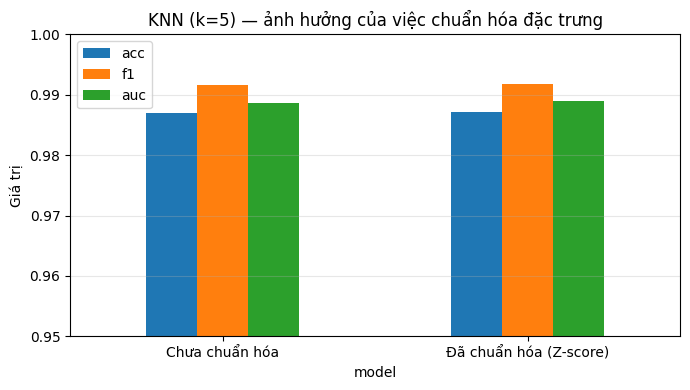

In [5]:
# KNN quyết định bằng KHOẢNG CÁCH, mà khoảng cách cộng dồn hiệu trên mọi
# chiều. Một đặc trưng có đơn vị lớn sẽ áp đảo các đặc trưng đơn vị nhỏ.
# Vì vậy sách vở thường nói "KNN bắt buộc phải chuẩn hóa". Ta ĐO THỬ thay vì
# tin ngay — kết quả trên ba bộ dữ liệu khác nhau không giống nhau.
rows = []
for tag, A, B in [("Chưa chuẩn hóa", X_tr_raw, X_te_raw),
                  ("Đã chuẩn hóa (Z-score)", X_tr, X_te)]:
    yp, ys, _ = fit_knn(A, y_tr, B, n_neighbors=5)
    rows.append(evaluate(y_te, yp, ys, tag))

scale_df = pd.DataFrame(rows).set_index("model").round(4)
print("KNN k=5 — ảnh hưởng của việc chuẩn hóa đặc trưng")
print(scale_df[["acc", "prec", "rec", "f1", "auc"]])
print(f"\nChênh lệch F1: {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(SCALE_COMMENT)

ax = scale_df[["acc", "f1", "auc"]].plot.bar(figsize=(7, 4), rot=0)
ax.set_title("KNN (k=5) — ảnh hưởng của việc chuẩn hóa đặc trưng")
ax.set_ylabel("Giá trị")
ax.set_ylim(SCALE_YLIM)
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A3. Chọn Số Láng Giềng k

       acc    prec     rec      f1     auc
k                                         
1   0.9857  0.9914  0.9901  0.9908  0.9805
3   0.9875  0.9903  0.9936  0.9919  0.9867
5   0.9872  0.9894  0.9942  0.9918  0.9890
7   0.9857  0.9886  0.9930  0.9908  0.9900
9   0.9859  0.9878  0.9940  0.9909  0.9907
11  0.9857  0.9875  0.9942  0.9908  0.9909
15  0.9847  0.9872  0.9930  0.9901  0.9911
21  0.9833  0.9848  0.9938  0.9893  0.9912
31  0.9824  0.9844  0.9930  0.9887  0.9907

→ k tốt nhất theo F1: k = 3  (F1 = 0.9919)
→ F1 tại k = 31: 0.9887

Nhận xét: k nhỏ thắng, nhưng chênh lệch giữa k tốt nhất và k = 31 chỉ
khoảng 0,003 → mô hình không quá nhạy với k trên bộ dữ liệu này. Đường cong
có đỉnh rồi đi xuống nhẹ là dạng bình thường, lành mạnh.


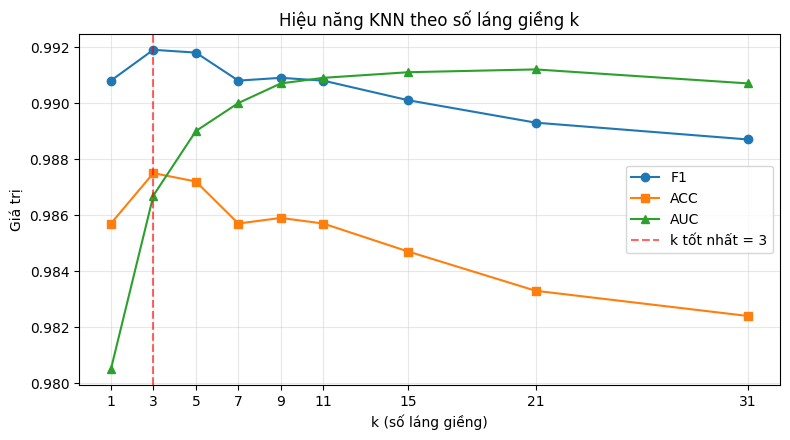

In [6]:
# k nhỏ  → biên quyết định gấp khúc, bám sát từng mẫu  → dễ overfit, nhạy nhiễu
#          (k = 1 nghĩa là mô hình chỉ sao chép nhãn của mẫu gần nhất)
# k lớn  → biên quyết định mượt, lấy ý kiến đa số rộng → dễ underfit, và lớp
#          thiểu số (tấn công) dễ bị lớp đa số lấn át trong phiếu bầu
rows = []
for k in K_GRID:
    yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k)
    rows.append(evaluate(y_te, yp, ys, k))

k_df = pd.DataFrame(rows).set_index("model").round(4)
k_df.index.name = "k"
print(k_df[["acc", "prec", "rec", "f1", "auc"]])

k_best = int(k_df["f1"].idxmax())
print(f"\n→ k tốt nhất theo F1: k = {k_best}  (F1 = {k_df.loc[k_best, 'f1']:.4f})")
print(f"→ F1 tại k = {K_GRID[-1]}: {k_df['f1'].iloc[-1]:.4f}")
print(KSWEEP_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, mk in [("f1", "o"), ("acc", "s"), ("auc", "^")]:
    ax.plot(k_df.index, k_df[col], marker=mk, label=col.upper())
ax.axvline(k_best, color="red", ls="--", alpha=.6, label=f"k tốt nhất = {k_best}")
ax.set_xlabel("k (số láng giềng)")
ax.set_ylabel("Giá trị")
ax.set_title("Hiệu năng KNN theo số láng giềng k")
ax.set_xticks(K_GRID)
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. So Sánh Metric Khoảng Cách & Trọng Số Phiếu

KNN k=3 — so sánh 3 metric × 2 kiểu trọng số
                       acc    prec     rec      f1     auc
model                                                     
manhattan|uniform   0.9913  0.9921  0.9967  0.9944  0.9885
manhattan|distance  0.9898  0.9921  0.9948  0.9934  0.9886
euclidean|uniform   0.9875  0.9903  0.9936  0.9919  0.9867
euclidean|distance  0.9868  0.9907  0.9922  0.9915  0.9861
chebyshev|uniform   0.9850  0.9869  0.9938  0.9903  0.9839
chebyshev|distance  0.9844  0.9878  0.9920  0.9899  0.9839

→ Cấu hình tốt nhất: metric=manhattan, weights=uniform  (F1 = 0.9944)

Nhận xét: Manhattan (L1) vượt Euclidean (L2). Khi số chiều lớn, L2 cộng
dồn bình phương nên một chiều nhiễu mạnh có thể chi phối toàn bộ khoảng
cách; L1 phân bổ đều hơn giữa các chiều. Chebyshev kém nhất vì chỉ nghe
theo đúng một chiều.


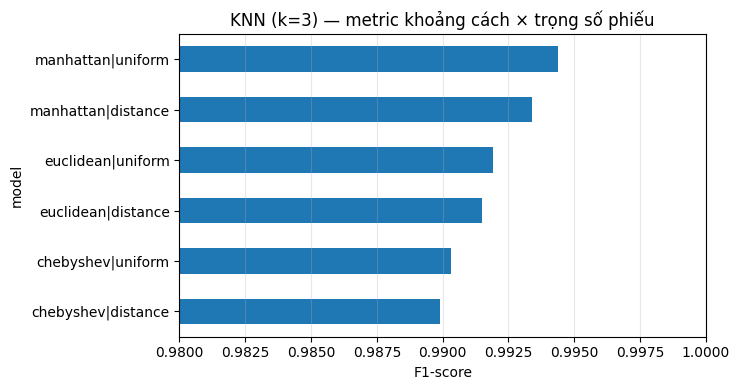

In [7]:
# euclidean (L2) : căn bậc hai tổng bình phương hiệu
# manhattan (L1) : tổng trị tuyệt đối hiệu — bền hơn với ngoại lai và theo
#                  thực nghiệm thường tốt hơn L2 khi số chiều cao
# chebyshev (L∞) : chỉ lấy hiệu lớn nhất trên một chiều, bỏ qua các chiều khác
#
# weights='uniform'  : mọi láng giềng một phiếu bằng nhau
# weights='distance' : láng giềng càng gần phiếu càng nặng, theo tỷ lệ 1/d
rows = []
for met in METRICS:
    for w in WEIGHTS:
        yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k_best,
                            metric=met, weights=w)
        rows.append(evaluate(y_te, yp, ys, f"{met}|{w}"))

combo_df = pd.DataFrame(rows).set_index("model").round(4)
print(f"KNN k={k_best} — so sánh {len(METRICS)} metric × {len(WEIGHTS)} kiểu trọng số")
print(combo_df[["acc", "prec", "rec", "f1", "auc"]].sort_values("f1", ascending=False))

combo_best = combo_df["f1"].idxmax()
best_metric, best_weights = combo_best.split("|")
print(f"\n→ Cấu hình tốt nhất: metric={best_metric}, weights={best_weights}"
      f"  (F1 = {combo_df.loc[combo_best, 'f1']:.4f})")
print(COMBO_COMMENT)

ax = combo_df["f1"].sort_values().plot.barh(figsize=(7.5, 4))
ax.set_xlabel("F1-score")
ax.set_title(f"KNN (k={k_best}) — metric khoảng cách × trọng số phiếu")
ax.set_xlim(COMBO_XLIM)
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A5. Số Chiều & Lời Nguyền Số Chiều (PCA)

evr = tỷ lệ phương sai được giữ lại sau khi giảm chiều
                  f1     auc     evr
n_components                        
2             0.9685  0.9445  0.2576
5             0.9834  0.9707  0.5243
10            0.9934  0.9876  0.7487
20            0.9921  0.9885  0.9310
72            0.9919  0.9867  1.0000

Nhận xét: giảm xuống 10 chiều cho F1 CAO HƠN dùng toàn bộ đặc trưng, dù
chỉ giữ khoảng 75% phương sai. Đây chính là lời nguyền số chiều: các chiều
bị loại chủ yếu mang nhiễu, và loại chúng làm khoảng cách sạch hơn.


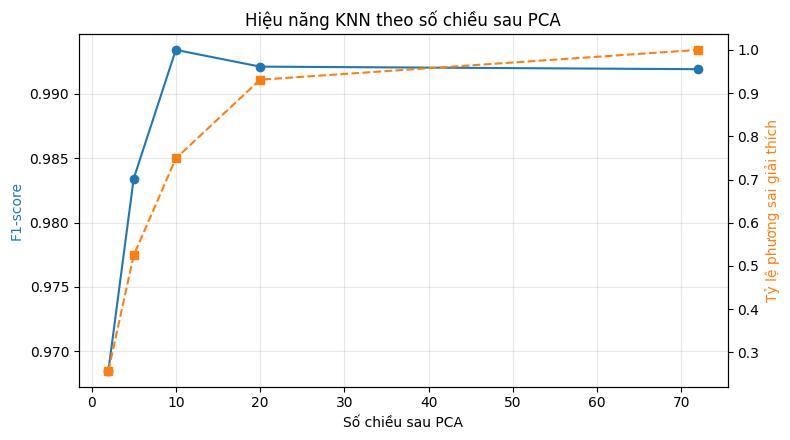

In [8]:
# Lời nguyền số chiều: khi số chiều tăng, khoảng cách từ một điểm tới mẫu gần
# nhất và tới mẫu xa nhất co lại gần bằng nhau → khái niệm "láng giềng" mất
# dần ý nghĩa, đồng thời chi phí tính khoảng cách tăng lên.
# PCA chiếu dữ liệu sang không gian ít chiều hơn mà vẫn giữ phần lớn phương sai.
rows = []
for nc in PCA_GRID:
    if nc >= X_tr.shape[1]:
        continue
    pca = PCA(n_components=nc, random_state=SEED).fit(X_tr)
    yp, ys, _ = fit_knn(pca.transform(X_tr), y_tr, pca.transform(X_te),
                        n_neighbors=k_best)
    r = evaluate(y_te, yp, ys, nc)
    r["evr"] = pca.explained_variance_ratio_.sum()
    rows.append(r)

# Mốc so sánh: dùng toàn bộ số chiều
yp, ys, _ = fit_knn(X_tr, y_tr, X_te, n_neighbors=k_best)
r = evaluate(y_te, yp, ys, X_tr.shape[1])
r["evr"] = 1.0
rows.append(r)

pca_df = pd.DataFrame(rows).set_index("model").round(4)
pca_df.index.name = "n_components"
print("evr = tỷ lệ phương sai được giữ lại sau khi giảm chiều")
print(pca_df[["f1", "auc", "evr"]])
print(PCA_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(pca_df.index, pca_df["f1"], marker="o", color="tab:blue", label="F1")
ax1.set_xlabel("Số chiều sau PCA")
ax1.set_ylabel("F1-score", color="tab:blue")
ax1.grid(alpha=.3)
ax2 = ax1.twinx()
ax2.plot(pca_df.index, pca_df["evr"], marker="s", ls="--", color="tab:orange")
ax2.set_ylabel("Tỷ lệ phương sai giải thích", color="tab:orange")
ax1.set_title("Hiệu năng KNN theo số chiều sau PCA")
plt.tight_layout()
plt.show()


### A6. Độ Trễ Suy Luận – Điểm Yếu Cốt Tử Của KNN

         ms_per_sample  samples_per_sec  mem_train_MB
n_train                                              
1000             0.134         7479.155         0.549
5000             0.174         5732.095         2.747
10000            0.143         6994.863         5.493
15534            0.164         6092.969         8.533

⚠ Con số tuyệt đối phụ thuộc cấu hình máy. Điều cần quan sát là XU HƯỚNG:
  tập train càng lớn thì mỗi dự đoán càng chậm, và toàn bộ tập train
  phải nằm trong bộ nhớ khi triển khai.

Nhận xét: với khoảng 15.000 mẫu train, mỗi dự đoán mất chừng 0,1 ms trên
một luồng xử lý — tương đương khoảng 10.000 luồng/giây. Một IDS đường trục
cần xử lý hàng trăm nghìn luồng/giây và sẽ tích lũy hàng triệu mẫu lịch sử,
lúc đó KNN không còn khả thi. Cây quyết định hay hồi quy logistic có chi phí
dự đoán hằng số nên phù hợp hơn cho triển khai trực tuyến.


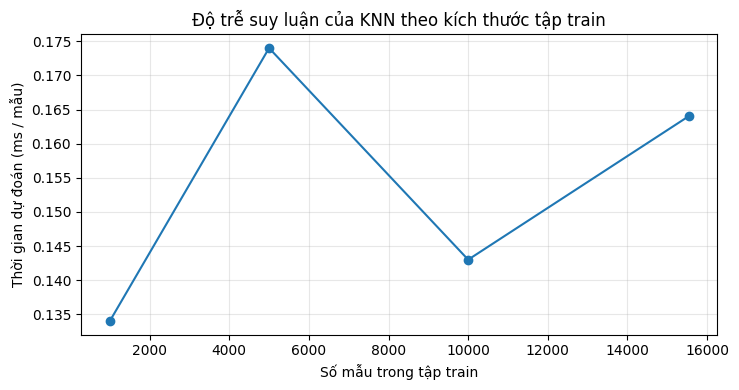

In [9]:
# KNN là "lazy learner": fit() gần như tức thì vì chỉ lưu dữ liệu, nhưng mỗi
# lần predict() phải đi tìm láng giềng trong TOÀN BỘ tập train. Chi phí suy
# luận vì thế tăng theo kích thước tập train — ngược hẳn với cây quyết định
# hay hồi quy logistic, nơi chi phí dự đoán là hằng số.
N_PROBE = 2000     # số mẫu dùng để đo thời gian
rows = []
for n in [1000, 5000, 10000, X_tr.shape[0]]:
    if n > X_tr.shape[0]:
        continue
    kn = KNeighborsClassifier(n_neighbors=k_best).fit(X_tr[:n], y_tr[:n])
    t0 = time.perf_counter()
    kn.predict(X_te[:N_PROBE])
    dt = time.perf_counter() - t0
    rows.append({"n_train": n,
                 "ms_per_sample": dt / N_PROBE * 1000,
                 "samples_per_sec": N_PROBE / dt,
                 "mem_train_MB": X_tr[:n].nbytes / 1024 / 1024})

lat_df = pd.DataFrame(rows).set_index("n_train").round(3)
print(lat_df)
print("\n⚠ Con số tuyệt đối phụ thuộc cấu hình máy. Điều cần quan sát là XU HƯỚNG:")
print("  tập train càng lớn thì mỗi dự đoán càng chậm, và toàn bộ tập train")
print("  phải nằm trong bộ nhớ khi triển khai.")
print(LATENCY_COMMENT)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(lat_df.index, lat_df["ms_per_sample"], marker="o")
ax.set_xlabel("Số mẫu trong tập train")
ax.set_ylabel("Thời gian dự đoán (ms / mẫu)")
ax.set_title("Độ trễ suy luận của KNN theo kích thước tập train")
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Mô Hình Cuối – Confusion Matrix & Đường Cong ROC

                                  acc    prec     rec      f1  f1_macro  \
model                                                                     
KNN (k=3, manhattan, uniform)  0.9913  0.9921  0.9967  0.9944    0.9875   
Random Forest (200 cây)        0.9920  0.9925  0.9973  0.9949    0.9886   

                                  auc  
model                                  
KNN (k=3, manhattan, uniform)  0.9885  
Random Forest (200 cây)        0.9939  

Confusion matrix KNN:  TN=1471  FP=41  FN=17  TP=5129
  FP = 41 cảnh báo giả | FN = 17 lần bỏ sót malware

              precision    recall  f1-score   support

      Benign     0.9886    0.9729    0.9807      1512
     Malware     0.9921    0.9967    0.9944      5146

    accuracy                         0.9913      6658
   macro avg     0.9903    0.9848    0.9875      6658
weighted avg     0.9913    0.9913    0.9913      6658


Nhận xét: KNN gần như bằng Random Forest về F1, nhưng AUC thấp hơn rõ.
Nguyên nhân: predict_proba của K

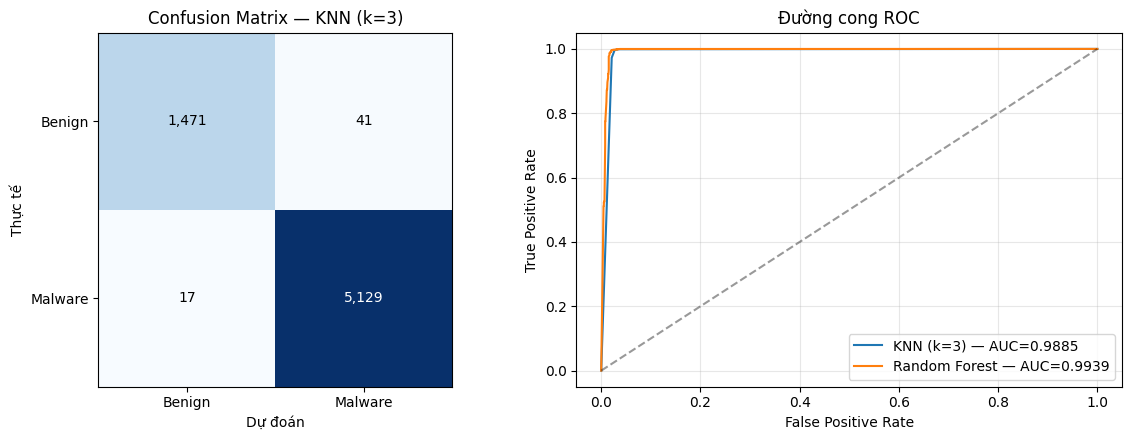

In [10]:
# Mô hình cuối dùng k, metric và weights tốt nhất đã tìm được ở A3 và A4.
# Random Forest 200 cây được huấn luyện trên cùng tập train để làm mốc so sánh.
y_pred, y_score, knn_final = fit_knn(
    X_tr, y_tr, X_te,
    n_neighbors=k_best, metric=best_metric, weights=best_weights)
knn_res = evaluate(y_te, y_pred, y_score,
                   f"KNN (k={k_best}, {best_metric}, {best_weights})")

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(X_tr, y_tr)
rf_score = rf.predict_proba(X_te)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([knn_res, rf_res]).set_index("model").round(4)
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix KNN:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[0].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[0].set_xticks([0, 1], TARGET_NAMES)
axes[0].set_yticks([0, 1], TARGET_NAMES)
axes[0].set_xlabel("Dự đoán")
axes[0].set_ylabel("Thực tế")
axes[0].set_title(f"Confusion Matrix — KNN (k={k_best})")

for nm, sc in [(f"KNN (k={k_best})", y_score), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Đường cong ROC")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Kiểm Chứng Bằng 5-Fold Cross-Validation

F1 từng fold : [0.994  0.9919 0.9945 0.9943 0.9925]
F1 trung bình: 0.9934 ± 0.0011
F1 của một lần chia train/test ở A7: 0.9944

Nhận xét: độ lệch chuẩn rất nhỏ → kết quả ổn định qua các lần chia khác
nhau, không phải do may mắn của một lần chia duy nhất.


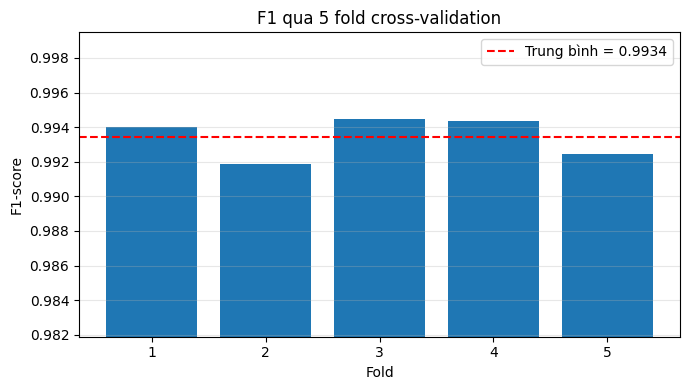

In [11]:
# Một lần chia train/test có thể "may mắn". K-fold chia dữ liệu thành k phần,
# lần lượt lấy một phần làm test → k kết quả, xem độ lệch chuẩn để biết mô
# hình có ổn định hay không.
#
# Scaler PHẢI nằm trong Pipeline: mỗi fold tự fit scaler trên phần train của
# riêng fold đó. Nếu chuẩn hóa toàn bộ dữ liệu rồi mới chia fold thì thông tin
# của fold validation đã rò rỉ vào scaler.
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=k_best, metric=best_metric,
                                 weights=best_weights)),
])

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
scores = cross_val_score(pipe, X_raw.values, y, cv=cv, scoring="f1", n_jobs=-1)

print(f"F1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A7: {knn_res['f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.01, max(scores) + 0.005)
ax.set_title(f"F1 qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Trên bộ CICMAL2017, chuẩn hóa Z-score gần như không làm thay đổi F1 — quy tắc "KNN bắt buộc phải chuẩn hóa" không phải lúc nào cũng đúng.
2. `k` nhỏ cho kết quả tốt nhất, nhưng mô hình không quá nhạy với `k`.
3. Manhattan (L1) vượt Euclidean (L2), phù hợp với lý thuyết về không gian nhiều chiều.
4. Giảm chiều bằng PCA *cải thiện* kết quả — các chiều bị loại chủ yếu mang nhiễu.
5. Random Forest ngang bằng về F1 nhưng vượt rõ về AUC, và chi phí dự đoán không tăng theo kích thước tập train.

**Câu hỏi thảo luận**

1. Xem lại bảng ở phần A2: điều gì ở bộ đặc trưng này khiến việc chuẩn hóa trở nên không quan trọng? Hãy kiểm tra những đặc trưng có biên độ lớn nhất và xét xem chúng có phải là đặc trưng phân biệt tốt không.
2. `k` nhỏ cho F1 cao nhất. Với dữ liệu thật nhiều nhiễu hơn tập huấn luyện, việc chọn `k` nhỏ có rủi ro gì?
3. Vì sao khoảng cách L1 thường hoạt động tốt hơn L2 khi số chiều cao?
4. Giảm xuống 10 chiều PCA cho F1 cao hơn dùng cả 72 chiều, dù chỉ giữ khoảng 75% phương sai. Giải thích hiện tượng này.
5. Dựa trên số đo ở phần A6, hãy lập luận xem KNN có phù hợp để triển khai trên một IDS xử lý 100.000 luồng/giây hay không. Nếu không, mô hình nào phù hợp hơn và vì sao?
6. Mô hình cuối vừa bỏ sót một số mẫu tấn công (FN) vừa báo giả một số mẫu bình thường (FP). Trong vận hành SOC, loại lỗi nào tốn kém hơn? Có cách nào điều chỉnh để đổi FN lấy FP không?
